## Load and Inspect the Dataset

In this step, we load the dataset and perform initial inspection to understand its structure, data types, and sample records.

### What we will check:
- Shape of the dataset 
- Data types of each column
- First few rows of the dataset

In [1]:
import pandas as pd

df = pd.read_csv("../data/ds_salaries.csv")

print("Shape of dataset:",df.shape)

print("\nData Types:\n", df.dtypes)

print("\nSample Rows:")
df.head()

Shape of dataset: (3755, 11)

Data Types:
 work_year              int64
experience_level      object
employment_type       object
job_title             object
salary                 int64
salary_currency       object
salary_in_usd          int64
employee_residence    object
remote_ratio           int64
company_location      object
company_size          object
dtype: object

Sample Rows:


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


## Check Missing Values

In this step, we check for missing values in the dataset.

#### Key Checks:
- Total missing values per column
- Percentage of missing values

In [2]:
df.isnull().sum()

work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

## Check Duplicate Rows

In this step, we check for duplicate rows in the dataset.

#### Key Checks:
- Number of duplicate rows
- Inspect duplicate records

In [3]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    duplicates = df[df.duplicated()]


duplicates.head()

Number of duplicate rows: 1171


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
115,2023,SE,FT,Data Scientist,150000,USD,150000,US,0,US,M
123,2023,SE,FT,Analytics Engineer,289800,USD,289800,US,0,US,M
153,2023,MI,FT,Data Engineer,100000,USD,100000,US,100,US,M
154,2023,MI,FT,Data Engineer,70000,USD,70000,US,100,US,M
160,2023,SE,FT,Data Engineer,115000,USD,115000,US,0,US,M


## Analyze Target Variable Distribution

In this step, we explore the distribution of the target variable (**Price**) to understand how prices are spread across the dataset.

This helps us detect:
- Whether the data is skewed
- Presence of outliers 
- Overall pattern of price distribution

In [4]:
df["salary_in_usd"].describe()

count      3755.000000
mean     137570.389880
std       63055.625278
min        5132.000000
25%       95000.000000
50%      135000.000000
75%      175000.000000
max      450000.000000
Name: salary_in_usd, dtype: float64

In [5]:
df["salary_in_usd"].value_counts().head(10)

salary_in_usd
100000    99
150000    98
120000    91
160000    84
130000    82
200000    64
135000    63
140000    63
145000    54
175000    51
Name: count, dtype: int64

## Salary Distribution

Visualizing the distribution of `salary_in_usd` to check for skewness and outliers.

### What we will check:
- Shape of the distribution (normal / right-skewed / left-skewed)
- Presence of extreme outliers
- Where most salaries are concentrated

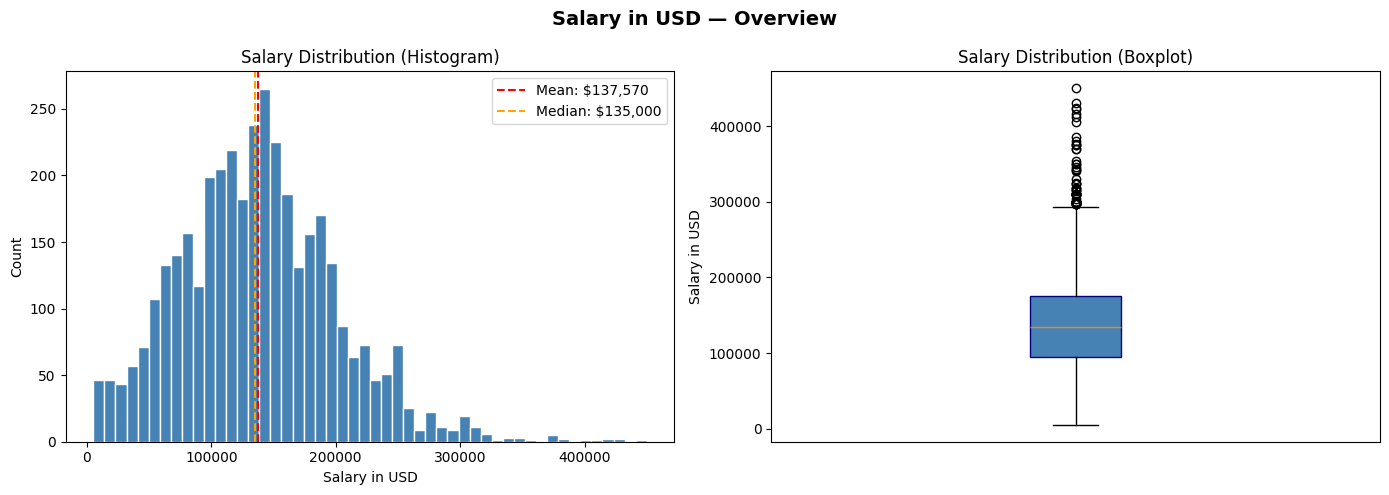

Skewness: 0.54  →  Right-skewed (long tail of high salaries)


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['salary_in_usd'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Salary Distribution (Histogram)')
axes[0].set_xlabel('Salary in USD')
axes[0].set_ylabel('Count')
axes[0].axvline(df['salary_in_usd'].mean(), color='red', linestyle='--', label=f"Mean: ${df['salary_in_usd'].mean():,.0f}")
axes[0].axvline(df['salary_in_usd'].median(), color='orange', linestyle='--', label=f"Median: ${df['salary_in_usd'].median():,.0f}")
axes[0].legend()

# Boxplot
axes[1].boxplot(df['salary_in_usd'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', color='navy'))
axes[1].set_title('Salary Distribution (Boxplot)')
axes[1].set_ylabel('Salary in USD')
axes[1].set_xticks([])

plt.suptitle('Salary in USD — Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

skewness = df['salary_in_usd'].skew()
print(f'Skewness: {skewness:.2f}  →  {"Right-skewed (long tail of high salaries)" if skewness > 0 else "Left-skewed"}')

## Average Salary by Experience Level

Experience level codes:
- **EN** — Entry-level
- **MI** — Mid-level
- **SE** — Senior
- **EX** — Executive / Director

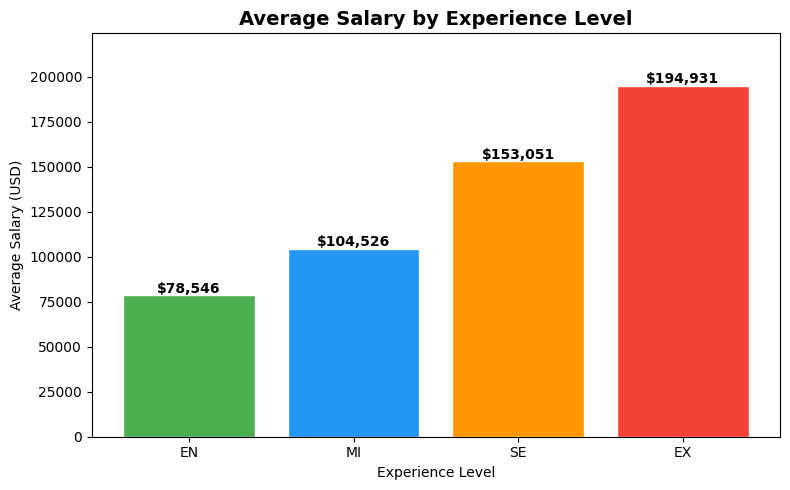

experience_level
EN     $78,546
MI    $104,526
SE    $153,051
EX    $194,931
Name: salary_in_usd, dtype: object


In [7]:
order = ['EN', 'MI', 'SE', 'EX']
avg_exp = df.groupby('experience_level')['salary_in_usd'].mean().reindex(order)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#4CAF50', '#2196F3', '#FF9800', '#F44336']
bars = ax.bar(avg_exp.index, avg_exp.values, color=colors, edgecolor='white')

for bar, val in zip(bars, avg_exp.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1500,
            f'${val:,.0f}', ha='center', fontsize=10, fontweight='bold')

ax.set_title('Average Salary by Experience Level', fontsize=14, fontweight='bold')
ax.set_xlabel('Experience Level')
ax.set_ylabel('Average Salary (USD)')
ax.set_ylim(0, avg_exp.max() * 1.15)
plt.tight_layout()
plt.show()

print(avg_exp.apply(lambda x: f'${x:,.0f}'))

## Salary by Employment Type

Employment type codes:
- **FT** — Full-time
- **PT** — Part-time
- **CT** — Contract
- **FL** — Freelance

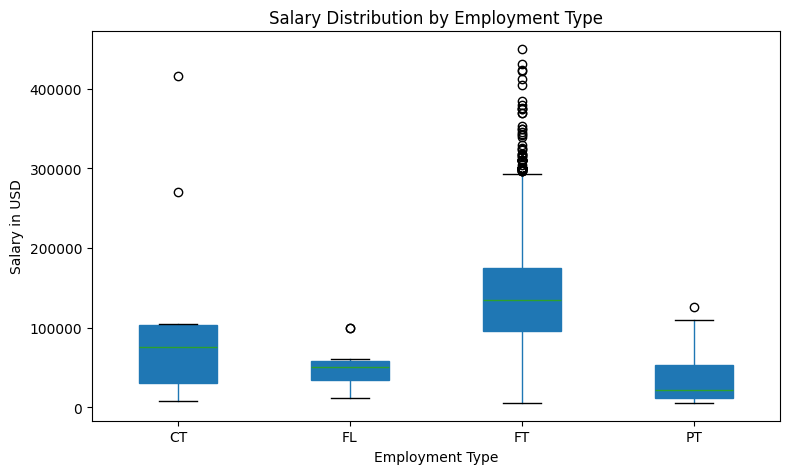

                 Count Avg Salary Median Salary
employment_type                                
CT                  10   $113,447       $75,000
FL                  10    $51,808       $50,000
FT                3718   $138,314      $135,000
PT                  17    $39,534       $21,669


C:\Users\User\AppData\Local\Temp\ipykernel_17992\4064431304.py:14: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  .applymap(lambda x: f'${x:,.0f}' if isinstance(x, float) else x))


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
df.boxplot(column='salary_in_usd', by='employment_type', ax=ax,
           patch_artist=True, grid=False)
ax.set_title('Salary Distribution by Employment Type')
plt.suptitle('')
ax.set_xlabel('Employment Type')
ax.set_ylabel('Salary in USD')
plt.tight_layout()
plt.show()

print(df.groupby('employment_type')['salary_in_usd']
        .agg(['count', 'mean', 'median'])
        .rename(columns={'count':'Count','mean':'Avg Salary','median':'Median Salary'})
        .applymap(lambda x: f'${x:,.0f}' if isinstance(x, float) else x))

## Top 10 Job Titles by Count

Finding the most common job titles in the dataset.

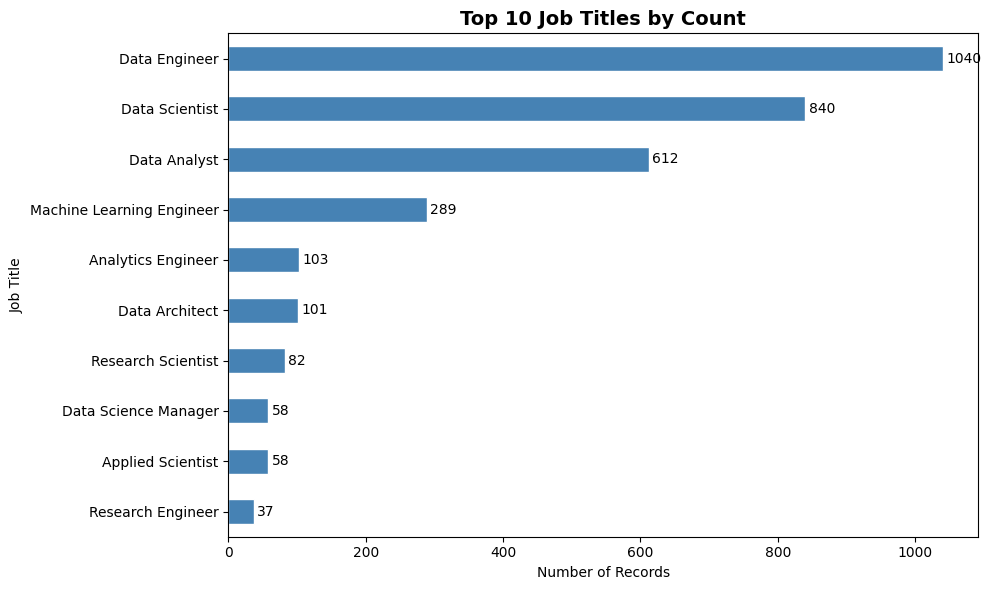

In [9]:
top_jobs = df['job_title'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 6))
top_jobs.sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Top 10 Job Titles by Count', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Records')
ax.set_ylabel('Job Title')

for i, v in enumerate(top_jobs.sort_values()):
    ax.text(v + 5, i, str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()

## Top 10 Highest-Paying Job Titles

Average salary for job titles that appear at least 10 times in the dataset.

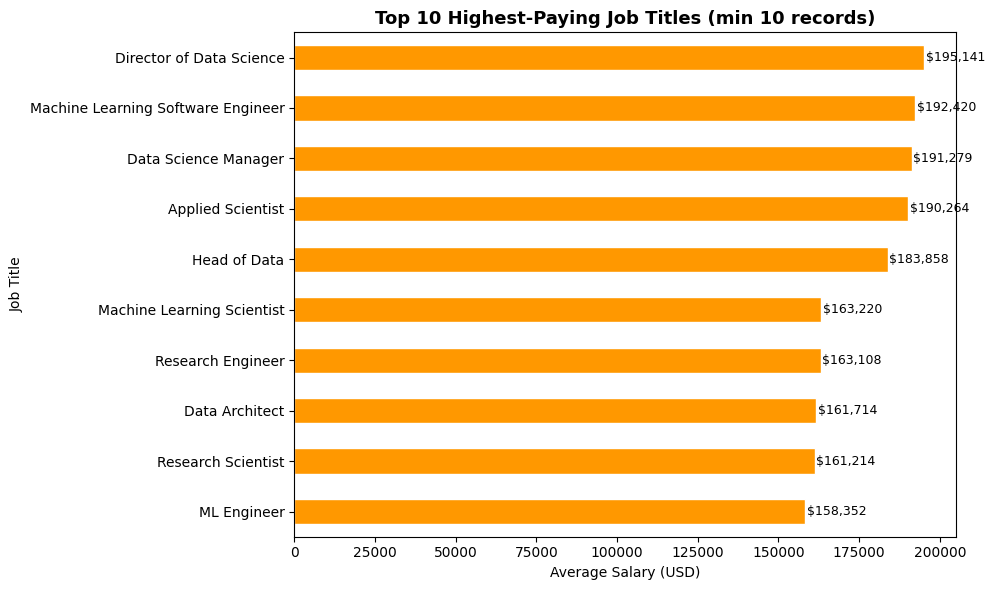

In [10]:
# Filter jobs with at least 10 records for reliability
job_counts = df['job_title'].value_counts()
common_jobs = job_counts[job_counts >= 10].index

top_salary_jobs = (df[df['job_title'].isin(common_jobs)]
                   .groupby('job_title')['salary_in_usd']
                   .mean()
                   .sort_values(ascending=False)
                   .head(10))

fig, ax = plt.subplots(figsize=(10, 6))
top_salary_jobs.sort_values().plot(kind='barh', ax=ax, color='#FF9800', edgecolor='white')
ax.set_title('Top 10 Highest-Paying Job Titles (min 10 records)', fontsize=13, fontweight='bold')
ax.set_xlabel('Average Salary (USD)')
ax.set_ylabel('Job Title')

for i, v in enumerate(top_salary_jobs.sort_values()):
    ax.text(v + 500, i, f'${v:,.0f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## Salary Trend Over the Years

How has the average data science salary changed year over year?

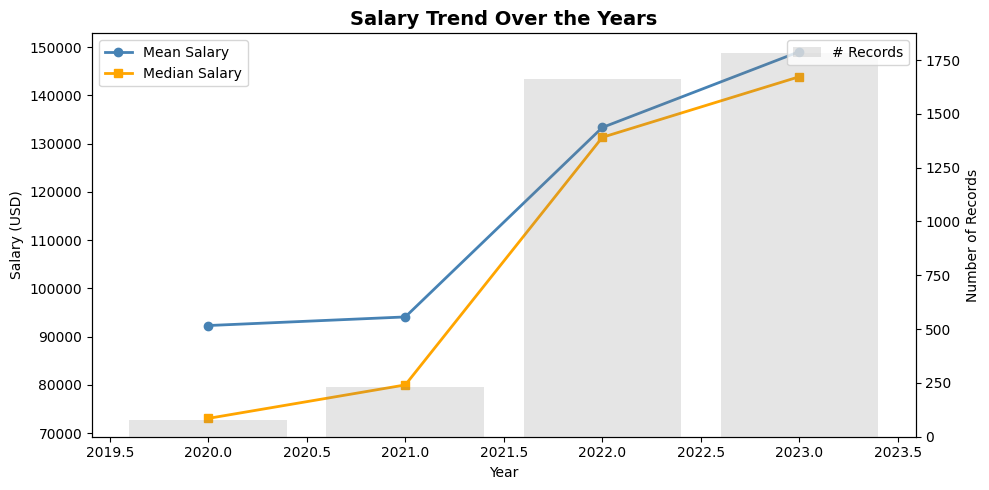

 Year    Avg Salary   Median  Records
 2020  92302.631579  73065.0       76
 2021  94087.208696  80000.0      230
 2022 133338.620793 131300.0     1664
 2023 149045.541176 143860.0     1785


In [11]:
yearly = df.groupby('work_year')['salary_in_usd'].agg(['mean', 'median', 'count']).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(yearly['work_year'], yearly['mean'], marker='o', color='steelblue', label='Mean Salary', linewidth=2)
ax1.plot(yearly['work_year'], yearly['median'], marker='s', color='orange', label='Median Salary', linewidth=2)
ax1.set_title('Salary Trend Over the Years', fontsize=14, fontweight='bold')
ax1.set_xlabel('Year')
ax1.set_ylabel('Salary (USD)')
ax1.legend(loc='upper left')

# Secondary axis for record count
ax2 = ax1.twinx()
ax2.bar(yearly['work_year'], yearly['count'], alpha=0.2, color='gray', label='# Records')
ax2.set_ylabel('Number of Records')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

print(yearly.rename(columns={'work_year':'Year','mean':'Avg Salary','median':'Median','count':'Records'}).to_string(index=False))

## Remote Work Distribution

`remote_ratio` values:
- **0** — On-site
- **50** — Hybrid
- **100** — Fully Remote

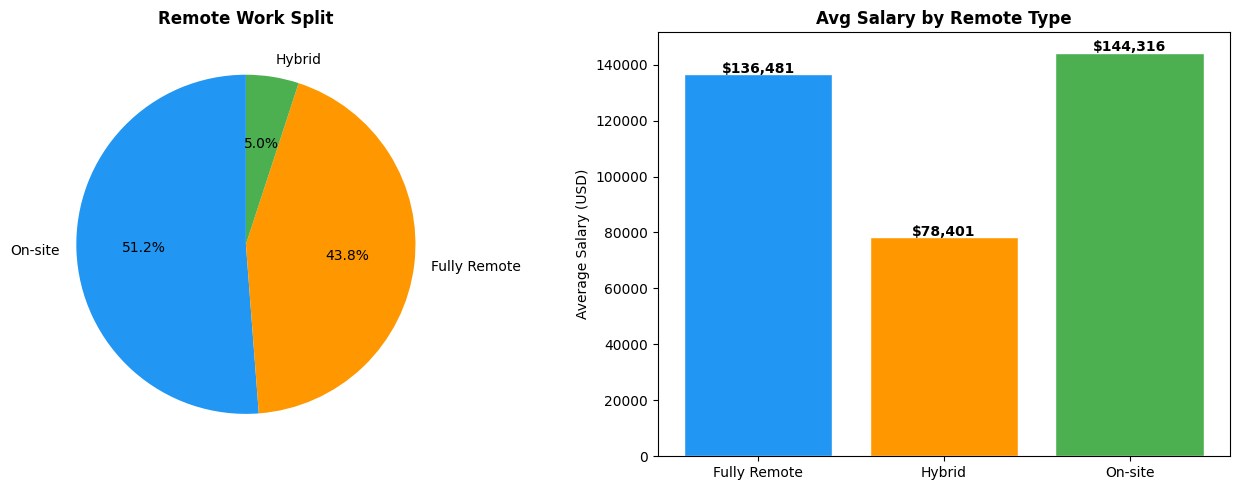

In [12]:
remote_map = {0: 'On-site', 50: 'Hybrid', 100: 'Fully Remote'}
df['remote_label'] = df['remote_ratio'].map(remote_map)

remote_counts = df['remote_label'].value_counts()
remote_salary = df.groupby('remote_label')['salary_in_usd'].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie chart — counts
axes[0].pie(remote_counts, labels=remote_counts.index, autopct='%1.1f%%',
            colors=['#2196F3','#FF9800','#4CAF50'], startangle=90)
axes[0].set_title('Remote Work Split', fontweight='bold')

# Bar chart — avg salary
bars = axes[1].bar(remote_salary.index, remote_salary.values,
                   color=['#2196F3','#FF9800','#4CAF50'], edgecolor='white')
axes[1].set_title('Avg Salary by Remote Type', fontweight='bold')
axes[1].set_ylabel('Average Salary (USD)')
for bar, val in zip(bars, remote_salary.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'${val:,.0f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## Salary by Company Size

Company size codes:
- **S** — Small (< 50 employees)
- **M** — Medium (50–250)
- **L** — Large (> 250)

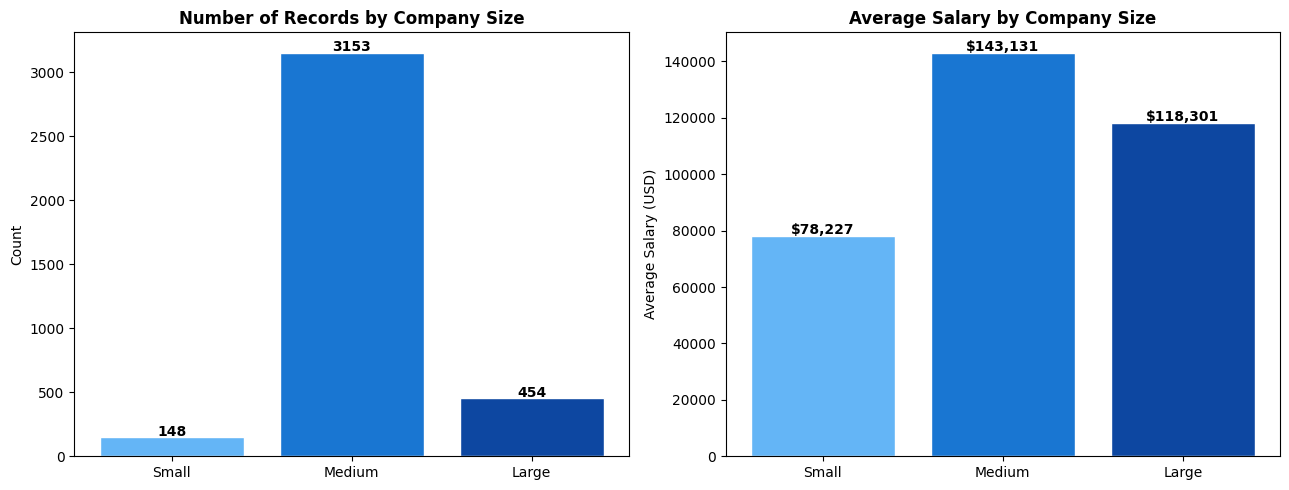

In [13]:
size_order = ['S', 'M', 'L']
size_labels = {'S': 'Small', 'M': 'Medium', 'L': 'Large'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Count of records
size_counts = df['company_size'].value_counts().reindex(size_order)
axes[0].bar([size_labels[s] for s in size_order], size_counts.values,
            color=['#64B5F6','#1976D2','#0D47A1'], edgecolor='white')
axes[0].set_title('Number of Records by Company Size', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(size_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Avg salary
size_salary = df.groupby('company_size')['salary_in_usd'].mean().reindex(size_order)
axes[1].bar([size_labels[s] for s in size_order], size_salary.values,
            color=['#64B5F6','#1976D2','#0D47A1'], edgecolor='white')
axes[1].set_title('Average Salary by Company Size', fontweight='bold')
axes[1].set_ylabel('Average Salary (USD)')
for i, v in enumerate(size_salary.values):
    axes[1].text(i, v + 500, f'${v:,.0f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## Top 10 Countries by Number of Jobs

Which countries have the most data science job records in this dataset?

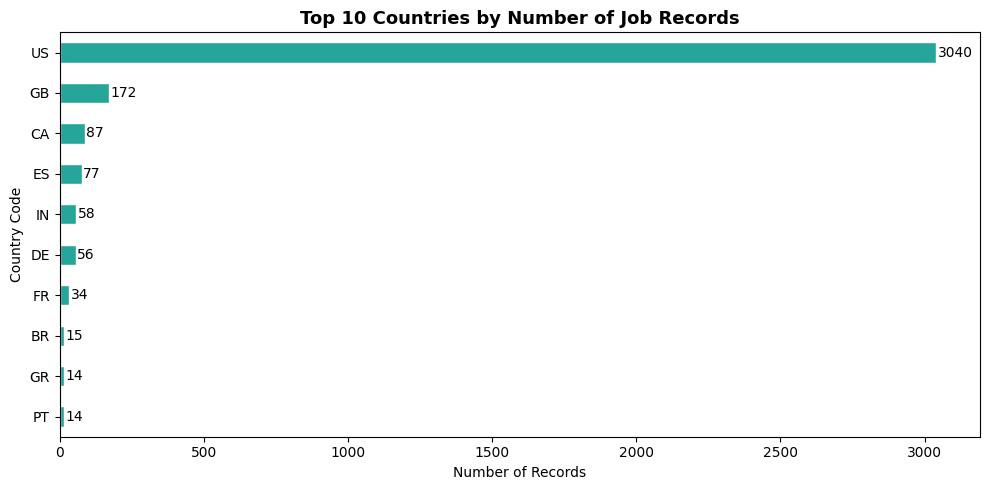


Average Salary by Country (top 10):
company_location
US    $151,822
CA    $131,918
DE     $88,289
GB     $86,890
FR     $66,139
ES     $57,676
GR     $51,792
PT     $50,539
BR     $40,579
IN     $30,198


In [14]:
top_countries = df['company_location'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
top_countries.sort_values().plot(kind='barh', ax=ax, color='#26A69A', edgecolor='white')
ax.set_title('Top 10 Countries by Number of Job Records', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Records')
ax.set_ylabel('Country Code')

for i, v in enumerate(top_countries.sort_values()):
    ax.text(v + 5, i, str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()

# Average salary per top country
top_country_salary = (df[df['company_location'].isin(top_countries.index)]
                      .groupby('company_location')['salary_in_usd']
                      .mean()
                      .sort_values(ascending=False))
print('\nAverage Salary by Country (top 10):')
print(top_country_salary.apply(lambda x: f'${x:,.0f}').to_string())

## Correlation Heatmap (Numeric Columns)

Checking if there is any linear correlation between the numeric features.

> Note: `remote_ratio` and `work_year` are the only numeric features besides salary.

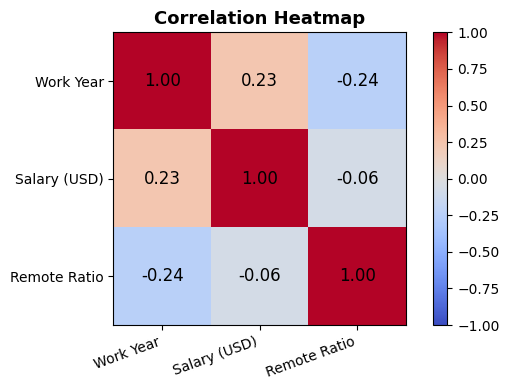

In [15]:
numeric_cols = df[['work_year', 'salary_in_usd', 'remote_ratio']]
corr = numeric_cols.corr()

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)

labels = ['Work Year', 'Salary (USD)', 'Remote Ratio']
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=20, ha='right')
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                fontsize=12, color='black')

ax.set_title('Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## EDA Summary

| Finding | Detail |
|---|---|
| Dataset shape | 3,755 rows × 11 columns |
| Missing values | None |
| Duplicates | 1,171 rows (~31%) |
| Salary range | $5,132 – $450,000 |
| Most common job | Data Scientist / Data Engineer |
| Highest-paid level | Executive (EX) |
| Dominant country | US (by far) |
| Salary trend | Increasing year over year |
| Remote work | Majority are fully remote |
